# Обнаружение фейковых научных новостей: TF-IDF + BiLSTM + CNN + ансамбль

**Кейс:** русскоязычные научные заголовки, `0 = правдивая`, `1 = фейковая`. Без трансформеров. Веса RNN/CNN выбираются **только на validation**, итоговый test используется один раз для финальной оценки.

**Порядок:** проверка качества → EDA → предобработка → групповое стратифицированное разбиение ~70/15/15 → baseline → диагностика стилевой утечки → Tokenizer → BiLSTM и CNN → подбор веса ансамбля → test → ошибки → проверка похожих текстов → отчёт и скачивание.

> ВАЖНО: если фейковые заголовки синтетические, высокая accuracy не равна способности определять фактическую достоверность новых новостей. Проверяются стилевые артефакты и дубликаты. Без исходных ссылок и разметки фактическую правильность меток установить невозможно. Пока нет аудио/ASR-транскриптов, WER и CER пока не рассчитываются.


## Ячейка 1. Импорты, конфигурация, seed=42

Небольшой embedding (128), умеренное число LSTM-нейронов (32) и регуляризация снижают риск переобучения на корпусе из нескольких тысяч текстов в каждом классе.

In [ ]:
# ЯЧЕЙКА 1 — библиотеки и воспроизводимость
import os
import re
import sys
import json
import random
import warnings
import subprocess
import importlib.util
from pathlib import Path
from collections import Counter

if importlib.util.find_spec('wordcloud') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'wordcloud'])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from wordcloud import WordCloud

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    balanced_accuracy_score, roc_auc_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

import scipy.sparse as sp
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
try:
    tf.config.experimental.enable_op_determinism()
except Exception as ex:
    print('Полная детерминированность недоступна:', str(ex)[:120])

sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_colwidth', 150)
warnings.filterwarnings('ignore', category=FutureWarning)

DATA_PATH = Path('/content/combined_dataset (2).csv')
if not DATA_PATH.exists():
    DATA_PATH = Path('combined_dataset (2).csv')
assert DATA_PATH.exists(), 'CSV не найден. Загрузите combined_dataset (2).csv в /content/.'

VOCAB_SIZE = 30_000
MAX_LEN = 20  # единое ограничение для BiLSTM и CNN; хватает для почти всех заголовков
EMBED_DIM = 128
BATCH_SIZE = 64
EPOCHS = 20
THRESHOLD = 0.5  # фиксируется заранее, НЕ подбирается на test

print('TensorFlow:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))
print('Файл:', DATA_PATH)

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Файл: /content/combined_dataset (2).csv


## Ячейка 2. Чтение исходного файла и базовый аудит

Не выбрасываем автоматически записи с конфликтной меткой: сначала считаем их, затем исключаем неоднозначные текстовые совпадения.

In [ ]:
# ЯЧЕЙКА 2 — структура, баланс и пропуски
raw = pd.read_csv(DATA_PATH, encoding='utf-8-sig')
raw.columns = raw.columns.str.strip()
assert {'title', 'is_fake'}.issubset(raw.columns), f'Ожидаются title и is_fake, есть {list(raw.columns)}'
raw = raw[['title', 'is_fake']].copy()

# Удаление фактических NaN выполняется позднее; здесь фиксируем исходную статистику.
print('Размер исходного датасета:', raw.shape)
print('\nТипы:\n', raw.dtypes)
print('\nПропуски:\n', raw.isna().sum())
print('\nМетки:\n', raw['is_fake'].value_counts(dropna=False))
print('Точные дубликаты заголовков:', raw['title'].duplicated().sum())
print('Дубликаты полных строк:', raw.duplicated().sum())

raw['is_fake'] = pd.to_numeric(raw['is_fake'], errors='raise')
assert raw['is_fake'].dropna().isin([0,1]).all(), 'Ожидаются только классы 0/1'

# При отсутствии timestamp/source их НЕ восстанавливаем из текста: временное покрытие неизвестно.
print('\nЧасть примеров каждого класса:')
for label in [0, 1]:
    print('\nКЛАСС', label)
    display(raw.loc[raw.is_fake.eq(label), ['title']].sample(
        min(5, int(raw.is_fake.eq(label).sum())), random_state=SEED
    ))

Размер исходного датасета: (11723, 2)

Типы:
 title      object
is_fake     int64
dtype: object

Пропуски:
 title      0
is_fake    0
dtype: int64

Метки:
 is_fake
0    5865
1    5858
Name: count, dtype: int64
Точные дубликаты заголовков: 0
Дубликаты полных строк: 0

Часть примеров каждого класса:

КЛАСС 0


,title
6875,На форуме «Технопром-2018» обсудили создание научных центров мирового уровня
6738,Найден универсальный сорбент для контроля токсичных элементов
367,Физики МГУ создали непредсказуемый генератор случайных чисел
870,Как изменения окружающей среды помогли древним людям адаптироваться
9001,Исследования плейстоценовых млекопитающих Вьетнама: первые итоги



КЛАСС 1


,title
10458,Простые и дешевые светодиоды на углеродных точках создали в ТПУ
7436,Учёные изучили синтез наночастиц оксида графена
3060,Ученые МГУ обнаружили связь между хроническим стрессом и снижением контрастной чувствительности глаз
50,Ученые СПбГУ разработали новый эффективный материал для фильтрации радиоактивной воды
8196,Исследователи ИК СО РАН И МИФИ создали нейросеть для анализа микроскопических изображений


## Ячейка 3. Объективные технические индикаторы качества
Отмечаем пропуски, слишком короткие строки, URL, управляющие/HTML-артефакты, отсутствие русских букв, подозрительно длинные строки. В заголовках с числами числа **не считаются шумом**

In [ ]:
# ЯЧЕЙКА 3 — метрики сырого текста, проверка артефактов
quality = raw.copy()
quality['title_str'] = quality['title'].fillna('').astype(str)
quality['char_len'] = quality.title_str.str.len()
quality['word_count'] = quality.title_str.str.findall(r'(?u)\b[а-яёa-z]+\b', flags=re.I).str.len()
quality['has_url'] = quality.title_str.str.contains(r'https?://|www\.', regex=True, case=False)
quality['has_digits'] = quality.title_str.str.contains(r'\d', regex=True)
quality['has_latin'] = quality.title_str.str.contains(r'[a-z]', regex=True, case=False)
quality['has_cyrillic'] = quality.title_str.str.contains(r'[а-яё]', regex=True, case=False)
quality['has_html_or_control'] = quality.title_str.str.contains(
    r'<[^>]+>|&(?:amp|quot|nbsp|lt|gt);|[\x00-\x08\x0b\x0c\x0e-\x1f]', regex=True
)
quality['empty'] = quality.title_str.str.strip().eq('')
quality['tech_noise'] = (
    quality['empty'] | (quality['word_count'] < 3) | (quality['char_len'] > 250) |
    quality['has_url'] | quality['has_html_or_control'] | ~quality['has_cyrillic']
)
TECH_NOISE_RATE_RAW = float(quality.tech_noise.mean())
print('Прокси-доля технического шума:', f'{TECH_NOISE_RATE_RAW:.2%}')
print('Прокси-доля чистых строк:', f'{1-TECH_NOISE_RATE_RAW:.2%}')
print('\nКачество по классам:')
display(quality.groupby('is_fake').agg(
    n=('title_str','size'), mean_words=('word_count','mean'),
    median_words=('word_count','median'), median_chars=('char_len','median'),
    urls=('has_url','mean'), digits=('has_digits','mean'),
    latin=('has_latin','mean'), tech_noise=('tech_noise','mean')
).round(3))
print('\nПримеры технически шумных строк:')
display(quality.loc[quality.tech_noise, ['title_str','is_fake','word_count']].head(15))

Прокси-доля технического шума: 0.07%
Прокси-доля чистых строк: 99.93%

Качество по классам:


,n,mean_words,median_words,median_chars,urls,digits,latin,tech_noise
is_fake,,,,,,,,
0,5865,8.463,8.0,65.0,0.0,0.144,0.072,0.001
1,5858,10.292,10.0,79.0,0.0,0.092,0.034,0.000



Примеры технически шумных строк:


,title_str,is_fake,word_count
567,Персонифицированная онкотерапия,0,2
1484,Арктическое теплоснабжение,0,2
2007,«Economic Challenges of COVID-19 Pandemic»,0,5
7291,Водоотталкивающая нанопленка,0,2
7866,"""Economic Challenges of COVID-19 Pandemic""",0,5
10064,Самозаряжающийся электромобиль,0,2
10313,Антибактериальная бактерия,0,2
11497,Неспешная высокоскоростная,0,2


## Ячейка 4. EDA до удаления цифр и пунктуации

Смотрим баланс, распределения количества слов и символов, характерные признаки классов. Если длина классов сильно различается, это потенциальная стилeвая утечка.

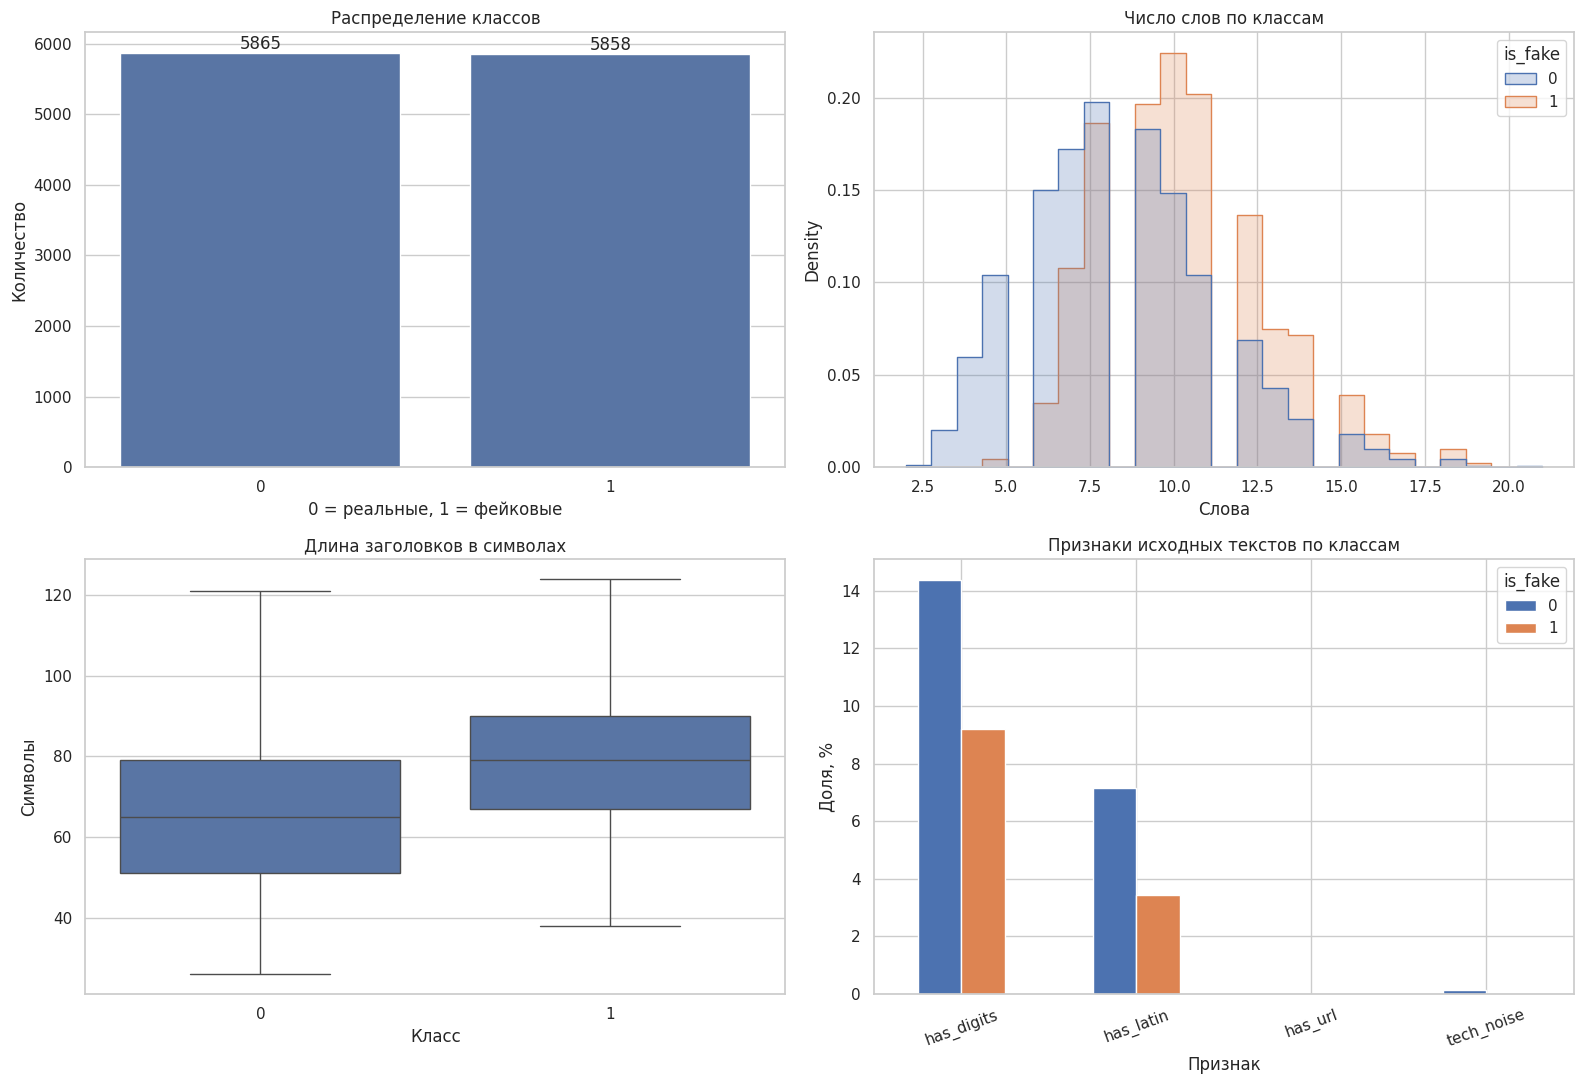

Квантили длины (слова):


,n_words
0.50,9.0
0.90,13.0
0.95,14.0
0.99,17.0
1.00,21.0


In [ ]:
# ЯЧЕЙКА 4 — EDA исходных текстов
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
sns.countplot(data=quality, x='is_fake', ax=axes[0,0])
axes[0,0].set(title='Распределение классов', xlabel='0 = реальные, 1 = фейковые', ylabel='Количество')
for c in axes[0,0].containers:
    axes[0,0].bar_label(c)

sns.histplot(data=quality, x='word_count', hue='is_fake', bins=25,
             common_norm=False, stat='density', element='step', ax=axes[0,1])
axes[0,1].set(title='Число слов по классам', xlabel='Слова')

sns.boxplot(data=quality, x='is_fake', y='char_len', showfliers=False, ax=axes[1,0])
axes[1,0].set(title='Длина заголовков в символах', xlabel='Класс', ylabel='Символы')

pcts = quality.groupby('is_fake')[['has_digits','has_latin','has_url','tech_noise']].mean().T * 100
pcts.plot(kind='bar', ax=axes[1,1])
axes[1,1].set(title='Признаки исходных текстов по классам', ylabel='Доля, %', xlabel='Признак')
axes[1,1].tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()

print('Квантили длины (слова):')
display(quality.word_count.quantile([0.5, 0.9, 0.95, 0.99, 1.0]).rename('n_words'))

## Ячейка 5. Нормализация и удаление стоп-слов

Предобработка выполняется *до split*, но использует только заранее фиксированные регулярные выражения и встроенный словарь без обучения на данных. Признаки TF-IDF и словарь `Tokenizer` строятся **строго на train**.

`не`, `ни`, `нет`, `без` специально **сохранены**: их удаление может изменить отрицание и смысл новости. Внимание: принудительное удаление чисел, предусмотренное заданием, способно ухудшить распознавание фактических искажений числовых величин.

In [ ]:
# ЯЧЕЙКА 5 — нормализация, конфликтные метки, дубликаты
RUSSIAN_STOPWORDS = set("""
а но и или да также тоже же бы б был была было были быть есть это этот эта эти этого
того тем тех то та те тут там здесь вот уже еще ещё только ведь даже потому поэтому
поскольку когда где куда откуда какой какая какое какие какого какой-то который которая
которое которые которых которым которыми кто что чего чем чей чья чьи чьих как каким
какими почему зачем сколько столько несколько все всего всех всем всеми весь вся всю
сам сама само сами самим самих самый самая самые свою свой свои своего своих своим
их его ее её ему ей им ими нас нам нами вас вам вами они она оно он мы вы ты я
меня тебе тобой себя себе собой у к ко из от до для по под над между через перед
при около после безо про об обо о во в на за со с то есть однако либо поскольку
может могут мог могла могли будет будут стали стало стал стали причем причём например
вроде среди более менее очень вовсе почти просто около всё все
""".split())
# Смыслообразующие отрицания оставляем, даже если добавили бы их в общий список.
RUSSIAN_STOPWORDS -= {'не', 'ни', 'нет', 'без'}

URL_PATTERN = re.compile(r'(?:https?://|www\.)\S+', flags=re.IGNORECASE)
DIGIT_PATTERN = re.compile(r'\d+')
PUNCT_PATTERN = re.compile(r'[^а-яёa-z\s]')
SPACE_PATTERN = re.compile(r'\s+')

def clean_title(value):
    s = str(value).lower().replace('ё','е')
    s = URL_PATTERN.sub(' ', s)
    s = DIGIT_PATTERN.sub(' ', s)
    s = PUNCT_PATTERN.sub(' ', s)
    words = [w for w in SPACE_PATTERN.sub(' ', s).split()
             if w not in RUSSIAN_STOPWORDS]
    return ' '.join(words)

before = len(raw)
df = raw.dropna(subset=['title','is_fake']).copy()
df['title'] = df.title.astype(str).str.strip()
df = df.loc[df.title.ne('')].copy()
df['is_fake'] = df.is_fake.astype('int32')
df['title_clean'] = df.title.map(clean_title)
df = df.loc[df.title_clean.ne('')].copy()

# По одной очищенной строке не должно быть противоречащих меток.
label_variants = df.groupby('title_clean').is_fake.nunique()
ambiguous_texts = set(label_variants.index[label_variants > 1])
ambiguous_rows = int(df.title_clean.isin(ambiguous_texts).sum())
if ambiguous_texts:
    df = df.loc[~df.title_clean.isin(ambiguous_texts)].copy()

before_dedup = len(df)
df = df.drop_duplicates(subset='title_clean', keep='first').reset_index(drop=True)
removed_exact_clean = before_dedup - len(df)
removed_total = before - len(df)

assert len(df) > 100 and df['is_fake'].nunique() == 2
assert df['title_clean'].is_unique
print('Было:', before, '| Стало:', len(df), '| Удалено суммарно:', removed_total)
print('Удалено строк с неоднозначными метками:', ambiguous_rows)
print('Повторные очищенные заголовки:', removed_exact_clean)
print('После обработки:', df.is_fake.value_counts().to_dict())
print('Доля сохранившихся записей:', f'{len(df)/before:.2%}')
print('\nПримеры до и после:')
display(df[['title','title_clean','is_fake']].sample(min(12,len(df)),random_state=SEED))

# Обязательное сохранение обработанного CSV; оригинальный не перезаписываем.
df_processed = df[['title','title_clean','is_fake']].copy()
df_processed.to_csv('/content/df_processed.csv', index=False, encoding='utf-8-sig')

Было: 11723 | Стало: 11428 | Удалено суммарно: 295
Удалено строк с неоднозначными метками: 126
Повторные очищенные заголовки: 169
После обработки: {0: 5815, 1: 5613}
Доля сохранившихся записей: 97.48%

Примеры до и после:


,title,title_clean,is_fake
7529,Химики из России и Израиля разработали способ восстановления белков,химики россии израиля разработали способ восстановления белков,0
11219,Магистранты МГУ предложили оригинальный метод определения запасов нефти с помощью смартфона,магистранты мгу предложили оригинальный метод определения запасов нефти помощью смартфона,1
4889,В ИЦиГ СО РАН доказали эффективность наночастиц оксида железа для тераностики ряда опухолей,ициг ран доказали эффективность наночастиц оксида железа тераностики ряда опухолей,1
8961,Астрофизики МГУ открыли оптический джет в черной дыре,астрофизики мгу открыли оптический джет черной дыре,0
4004,"Ученые выяснили, как особенности строения легких связаны с проявлением аутизма у детей",ученые выяснили особенности строения легких связаны проявлением аутизма детей,1
3265,Экологи СФУ разработали способ использования отходов пивного производства в качестве удобрения,экологи сфу разработали способ использования отходов пивного производства качестве удобрения,1
11233,Материаловеды оценили влияние металлических добавок на скорость горения ракетного топлива,материаловеды оценили влияние металлических добавок скорость горения ракетного топлива,0
9983,Нейронные сети научились узнавать свыше 90% фотографий растений Франции,нейронные сети научились узнавать свыше фотографий растений франции,1
900,"В 2018 году начнется производство разработанных в ДВФУ ""умных"" солнечных станций",году начнется производство разработанных двфу умных солнечных станций,1
7856,"Ученые предложили, как при разделении нефти снизить потери энергии",ученые предложили разделении нефти снизить потери энергии,0


## Ячейка 6. Расширенный EDA: токены, биграммы и облака слов

Частотность по классам даёт полезный сигнал об источниковых и тематических различиях. Облако слов — описательная визуализация, а не доказательство ложности.

Статистика длины после очистки:
count    11428.00
mean         7.77
std          2.10
min          2.00
50%          8.00
90%         11.00
95%         11.00
99%         13.00
max         18.00
Name: title_clean, dtype: float64
Доля заголовков, длиннее MAX_LEN=20: 0.00%


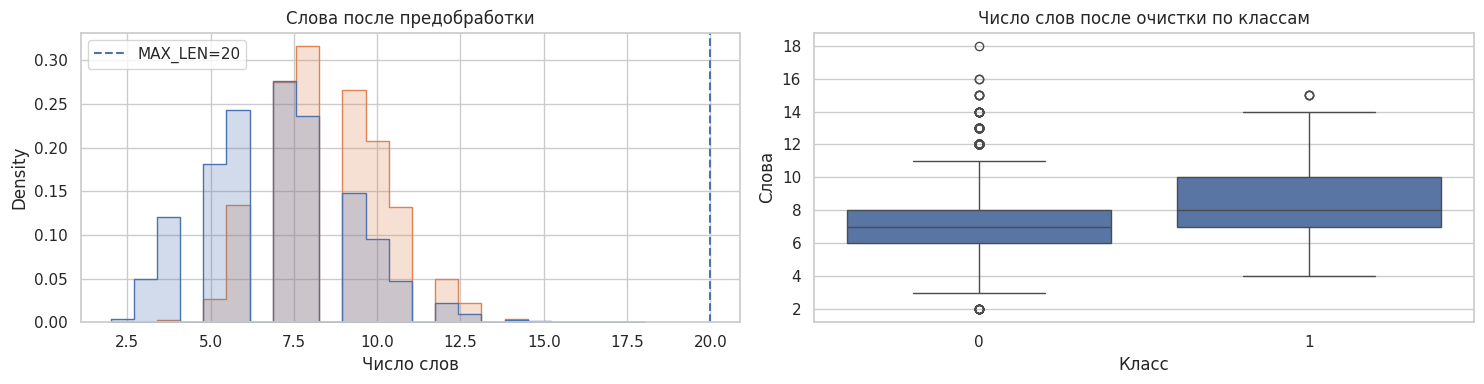


 Реальные


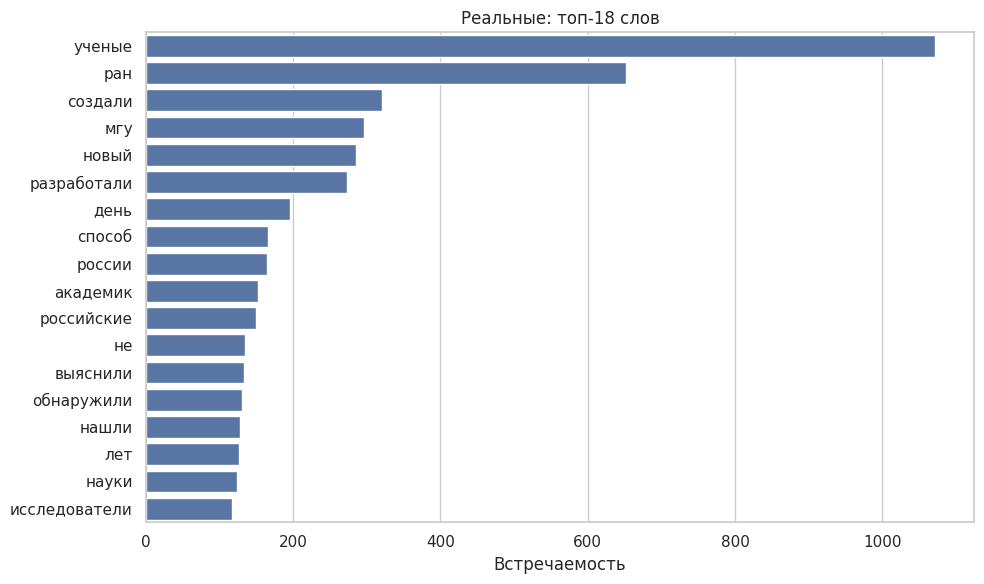

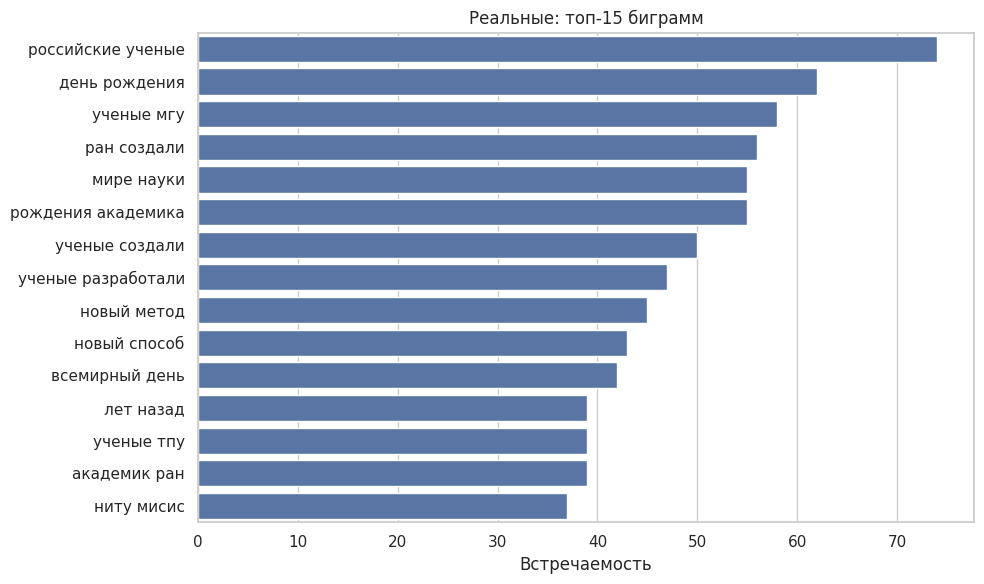


 Фейки


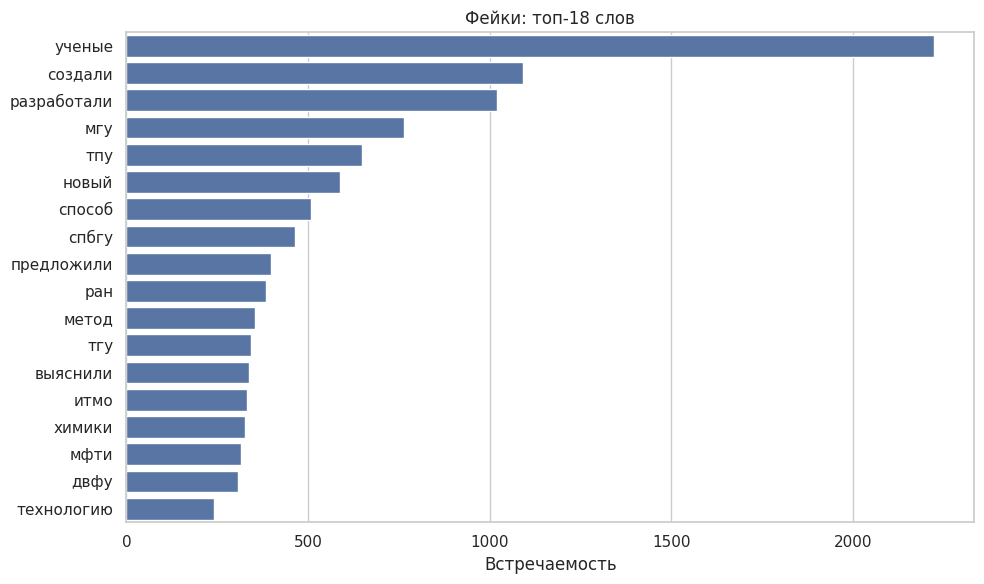

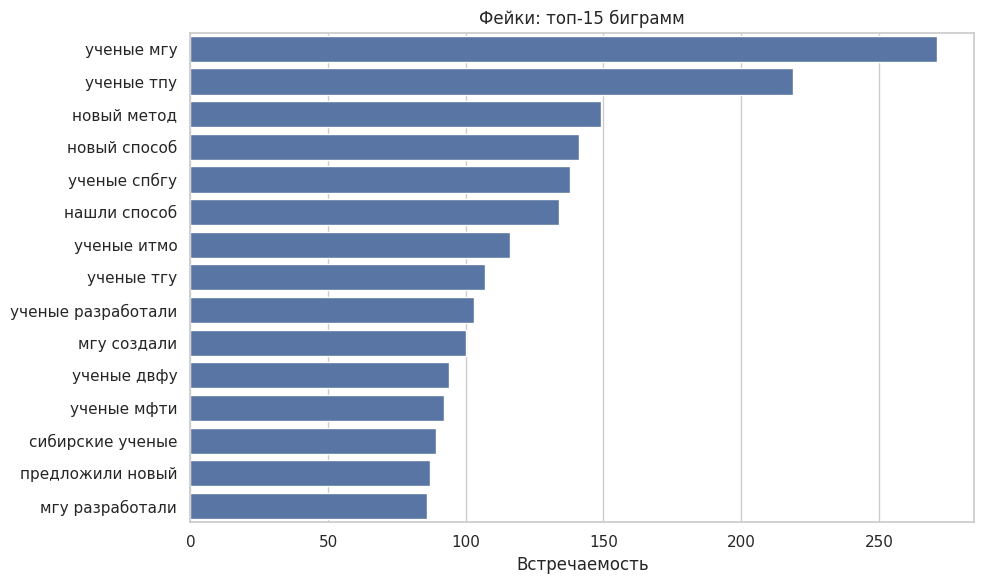

Шрифт кириллицы не найден: пропускаем WordCloud, barplot уже создан.


In [ ]:
# ЯЧЕЙКА 6 — статистика слов и частотные визуализации
clean_lengths = df.title_clean.str.split().str.len()
print('Статистика длины после очистки:')
print(clean_lengths.describe(percentiles=[.5,.9,.95,.99]).round(2))
print(f'Доля заголовков, длиннее MAX_LEN={MAX_LEN}: {(clean_lengths > MAX_LEN).mean():.2%}')

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
sns.histplot(data=df.assign(tokens=clean_lengths), x='tokens', hue='is_fake',
             bins=23, stat='density', common_norm=False, element='step', ax=ax[0])
ax[0].axvline(MAX_LEN, linestyle='--', label=f'MAX_LEN={MAX_LEN}')
ax[0].legend()
ax[0].set(title='Слова после предобработки', xlabel='Число слов')
sns.boxplot(data=df.assign(tokens=clean_lengths), x='is_fake', y='tokens', ax=ax[1])
ax[1].set(title='Число слов после очистки по классам', xlabel='Класс', ylabel='Слова')
plt.tight_layout(); plt.show()


def show_top_ngrams(texts, ngram_range=(1,1), top_k=20, title=''):
    vec = CountVectorizer(ngram_range=ngram_range, max_features=20_000)
    mat = vec.fit_transform(texts)
    freqs = np.asarray(mat.sum(axis=0)).ravel()
    order = np.argsort(freqs)[-top_k:][::-1]
    names = vec.get_feature_names_out()
    out = pd.DataFrame({'term':names[order],'count':freqs[order]})
    plt.figure(figsize=(10, 6))
    sns.barplot(data=out, x='count', y='term')
    plt.title(title); plt.xlabel('Встречаемость'); plt.ylabel('')
    plt.tight_layout(); plt.show()
    return out

for label, label_name in [(0,'Реальные'),(1,'Фейки')]:
    texts = df.loc[df.is_fake.eq(label),'title_clean']
    print('\n',label_name)
    show_top_ngrams(texts, (1,1), 18, f'{label_name}: топ-18 слов')
    show_top_ngrams(texts, (2,2), 15, f'{label_name}: топ-15 биграмм')

# Шрифт с кириллицей: Colab чаще всего содержит DejaVuSans.ttf.
font_candidates = [
    '/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf',
    '/usr/share/fonts/truetype/liberation2/LiberationSans-Regular.ttf'
]
font_path = next((p for p in font_candidates if Path(p).exists()), None)
if font_path is None:
    print('Шрифт кириллицы не найден: пропускаем WordCloud, barplot уже создан.')
else:
    fig, axes = plt.subplots(1, 2, figsize=(17, 6))
    for ax, (label, label_name) in zip(axes, [(0,'Реальные'),(1,'Фейки')]):
        corpus = ' '.join(df.loc[df.is_fake.eq(label), 'title_clean'])
        cloud = WordCloud(width=1100, height=600, background_color='white',
                          collocations=False, font_path=font_path,
                          max_words=120, random_state=SEED).generate(corpus)
        ax.imshow(cloud, interpolation='bilinear')
        ax.axis('off'); ax.set_title(f'Облако слов: {label_name}')
    plt.tight_layout(); plt.show()

## Ячейка 7. Группировка почти одинаковых заголовков + стратифицированное разбиение 70/15/15

Обычный `train_test_split` здесь опасен: в исходном CSV есть группы заголовков, почти полностью повторяющих друг друга и различающихся названием университета. Поэтому сначала строим **граф семантически близких по формулировке текстов** по символьным TF-IDF n-граммам (cosine ≥ 0.90); компоненты связности становятся группами. Затем используем `StratifiedGroupKFold` (20 фолдов): 14 фолдов train, 3 val, 3 test. Пропорция получается около 70/15/15 при сохранении баланса классов и запрете пересечения групп. Это более честный тест, чем обычный стратифицированный split.

Группировка использует только тексты, без меток для построения сходства. **Веса TF-IDF классификатора и словарь Tokenizer по-прежнему обучаются строго на train.** Наличие групп с обоими классами не исправляет возможные ошибки фактической разметки — такие группы будут отдельно подсчитаны.

In [ ]:
# ЯЧЕЙКА 7 — защита от near-duplicate leakage, потом 70/15/15
from sklearn.model_selection import StratifiedGroupKFold

# Символьный TF-IDF служит исключительно для группировки похожих строк перед split.
# Порог 0.90 более консервативен, чем диагностический порог 0.95.
GROUP_SIM_THRESHOLD = 0.90
char_group_vec = TfidfVectorizer(
    analyzer='char', ngram_range=(3,5), max_features=50_000,
    sublinear_tf=True, dtype=np.float32
)
all_char = char_group_vec.fit_transform(df.title_clean)
n_samples = len(df)
parents = np.arange(n_samples, dtype=np.int32)
ranks = np.zeros(n_samples, dtype=np.int8)

def find_group(i):
    while parents[i] != i:
        parents[i] = parents[parents[i]]
        i = parents[i]
    return int(i)

def union_group(i, j):
    a, b = find_group(i), find_group(j)
    if a == b:
        return
    if ranks[a] < ranks[b]:
        a, b = b, a
    parents[b] = a
    if ranks[a] == ranks[b]:
        ranks[a] += 1

# Умножение выполняется пакетами, чтобы не создавать плотную матрицу N x N.
edge_count = 0
for start in range(0, n_samples, 64):
    sims = (all_char[start:start+64] @ all_char.T).tocoo()
    candidate_mask = (
        (sims.data >= GROUP_SIM_THRESHOLD) &
        (sims.row + start < sims.col)
    )
    for a, b in zip(sims.row[candidate_mask] + start,
                    sims.col[candidate_mask]):
        union_group(int(a), int(b))
    edge_count += int(candidate_mask.sum())

roots = np.array([find_group(i) for i in range(n_samples)])
_, group_ids = np.unique(roots, return_inverse=True)
df['group_id'] = group_ids

group_sizes = df.groupby('group_id').size()
conflict_groups = df.groupby('group_id').is_fake.nunique().gt(1)
num_mixed_groups = int(conflict_groups.sum())
num_mixed_rows = int(group_sizes.loc[conflict_groups[conflict_groups].index].sum())
print('Рёбер сходства:', edge_count)
print('Всего групп:',len(group_sizes),'| групп из 2+ заголовков:',int((group_sizes>1).sum()))
print('Группы с метками обоих классов:',num_mixed_groups,
      '| строк в них:',num_mixed_rows)
if num_mixed_groups:
    print('ВАЖНО: похожие формулировки с разными метками — возможные ошибки')
    print('разметки или шаблонные изменения смысла. Для оценки требуется фактчекинг.')

# 20 фолдов позволяют разделить 14/3/3 ~ 70% / 15% / 15%.
# Сохранение целых групп важнее абсолютного совпадения числа строк.
fold_assign = np.empty(n_samples,dtype=np.int8)
sgkf = StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=SEED)
for fold, (_, held_idx) in enumerate(sgkf.split(
        np.zeros((n_samples,1)), df.is_fake.to_numpy(), group_ids)):
    fold_assign[held_idx] = fold

train_idx = np.flatnonzero(fold_assign < 14)
val_idx = np.flatnonzero((fold_assign >= 14) & (fold_assign < 17))
test_idx = np.flatnonzero(fold_assign >= 17)

train_df = df.iloc[train_idx].reset_index(drop=True)
val_df = df.iloc[val_idx].reset_index(drop=True)
test_df = df.iloc[test_idx].reset_index(drop=True)

x_train = train_df.title_clean.to_numpy()
x_val = val_df.title_clean.to_numpy()
x_test = test_df.title_clean.to_numpy()
y_train = train_df.is_fake.to_numpy(dtype='int32')
y_val = val_df.is_fake.to_numpy(dtype='int32')
y_test = test_df.is_fake.to_numpy(dtype='int32')

for name,d in [('TRAIN',train_df),('VAL',val_df),('TEST',test_df)]:
    print(name,'N=',len(d),'share=',f'{len(d)/len(df):.2%}',
          'fake_rate=',f'{d.is_fake.mean():.2%}')

assert set(train_df.group_id).isdisjoint(val_df.group_id)
assert set(train_df.group_id).isdisjoint(test_df.group_id)
assert set(val_df.group_id).isdisjoint(test_df.group_id)
assert set(train_df.title_clean).isdisjoint(val_df.title_clean)
assert set(train_df.title_clean).isdisjoint(test_df.title_clean)
assert set(val_df.title_clean).isdisjoint(test_df.title_clean)
assert min(map(len,[train_idx,val_idx,test_idx]))>0
print('Проверка: ни одна near-duplicate группа не пересекает выборки.')

Рёбер сходства: 8460
Всего групп: 7901 | групп из 2+ заголовков: 1173
Группы с метками обоих классов: 496 | строк в них: 2255
ВАЖНО: похожие формулировки с разными метками — возможные ошибки
разметки или шаблонные изменения смысла. Для оценки требуется фактчекинг.
TRAIN N= 7967 share= 69.71% fake_rate= 48.94%
VAL N= 1784 share= 15.61% fake_rate= 50.34%
TEST N= 1677 share= 14.67% fake_rate= 48.66%
Проверка: ни одна near-duplicate группа не пересекает выборки.


## Ячейка 8. Baseline: TF-IDF (1–2 граммы) + Logistic Regression

`max_features=30000` ограничивает словарь, `sublinear_tf=True` сглаживает частоты частых слов; балансировка классов задана, хотя корпус почти сбалансирован. `fit` проводится только на train. На данном этапе оценивается **validation** после группового разделения; test открывается в финальном сравнении всех моделей.

In [ ]:
# ЯЧЕЙКА 8 — обязательный baseline
vectorizer = TfidfVectorizer(max_features=30_000, ngram_range=(1,2),
                             sublinear_tf=True, min_df=1)
X_train_tfidf = vectorizer.fit_transform(x_train)
X_val_tfidf = vectorizer.transform(x_val)

baseline = LogisticRegression(
    max_iter=3000, class_weight='balanced', solver='liblinear',
    C=1.0, random_state=SEED
)
baseline.fit(X_train_tfidf, y_train)
p_base_val = baseline.predict_proba(X_val_tfidf)[:,1]
pred_base_val = (p_base_val >= THRESHOLD).astype(int)

print('TF-IDF словарь:',len(vectorizer.vocabulary_))
print('BASELINE validation accuracy:',round(accuracy_score(y_val,pred_base_val),4))
print('BASELINE validation F1:',round(f1_score(y_val,pred_base_val,zero_division=0),4))
print(classification_report(y_val,pred_base_val,
                            target_names=['real (0)','fake (1)'],zero_division=0))

# Слова, на которые LR чаще ориентируется в каждом направлении.
coef = baseline.coef_.ravel()
terms = vectorizer.get_feature_names_out()
for name, order in [('Класс 0',np.argsort(coef)[:20]),
                    ('Класс 1',np.argsort(coef)[-20:][::-1])]:
    print(name, list(zip(terms[order],np.round(coef[order],3))))

TF-IDF словарь: 30000
BASELINE validation accuracy: 0.8459
BASELINE validation F1: 0.8508
              precision    recall  f1-score   support

    real (0)       0.86      0.82      0.84       886
    fake (1)       0.83      0.87      0.85       898

    accuracy                           0.85      1784
   macro avg       0.85      0.85      0.85      1784
weighted avg       0.85      0.85      0.85      1784

Класс 0 [('ран', np.float64(-2.854)), ('день', np.float64(-2.667)), ('академик', np.float64(-2.216)), ('российские', np.float64(-2.101)), ('covid', np.float64(-2.078)), ('науки', np.float64(-2.0)), ('не', np.float64(-1.977)), ('университета итмо', np.float64(-1.778)), ('нияу мифи', np.float64(-1.291)), ('академика', np.float64(-1.187)), ('мире науки', np.float64(-1.1)), ('сергеев', np.float64(-1.089)), ('ран создали', np.float64(-1.088)), ('рф', np.float64(-1.087)), ('двфу дво', np.float64(-1.068)), ('рождения', np.float64(-1.057)), ('ран нгу', np.float64(-1.04)), ('александр'

## Ячейка 9. Диагностика стилевой утечки — без содержимого слов

Проверяем, может ли простая логистическая регрессия отличать классы **только** по количеству слов/символов, цифрам, латинице и знакам препинания. Если да — высокая точность NLP-моделей может быть связана с особенностями происхождения данных. Это диагностический инструмент, **не дополнительный классификатор в ансамбле**.

In [ ]:
# ЯЧЕЙКА 9 — style-only sanity check (без содержания слов)
def style_features(series):
    s = series.fillna('').astype(str)
    length = s.str.len().clip(lower=1)
    return pd.DataFrame({
        'chars': s.str.len(),
        'words': s.str.split().str.len(),
        'mean_word_length': s.apply(
            lambda t: float(np.mean([len(w) for w in t.split()])) if t.split() else 0.0),
        'digits': s.str.count(r'\d'),
        'latin': s.str.count(r'[A-Za-z]'),
        'upper_ratio': s.str.count(r'[A-ZА-ЯЁ]') / length,
        'question': s.str.count(r'\?'),
        'exclamation': s.str.count(r'!'),
        'quotes': s.str.count(r'[«»"\']'),
        'dash': s.str.count(r'[-—–]'),
        'commas': s.str.count(','),
        'colon': s.str.count(':'),
        'parentheses': s.str.count(r'[()]'),
    })

style_train = style_features(train_df.title)
style_val = style_features(val_df.title)
style_test = style_features(test_df.title)
style_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight='balanced',random_state=SEED,max_iter=2000)
)
style_model.fit(style_train, y_train)
p_style_val = style_model.predict_proba(style_val)[:,1]
acc_style_val = accuracy_score(y_val,p_style_val>=0.5)
auc_style_val = roc_auc_score(y_val,p_style_val)
print(f'Стилевой диагностический классификатор: val accuracy={acc_style_val:.4f}, ROC-AUC={auc_style_val:.4f}')
if auc_style_val > 0.70:
    print('ПРЕДУПРЕЖДЕНИЕ: различия формы заголовков заметно связаны с меткой.')

Стилевой диагностический классификатор: val accuracy=0.6928, ROC-AUC=0.7638
ПРЕДУПРЕЖДЕНИЕ: различия формы заголовков заметно связаны с меткой.


## Ячейка 10. Общая токенизация для обеих нейросетей

Один обученный **на train** `Tokenizer`, единый `MAX_LEN=20`, `padding='post'` и `truncating='post'` для BiLSTM/CNN. `oov_token='<unk>'` предотвращает ошибку на новых словах.

In [ ]:
# ЯЧЕЙКА 10 — токенизация (без fit на validation/test)
tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token='<unk>',
                      filters='', lower=False)
tokenizer.fit_on_texts(x_train.tolist())

def encode(texts):
    sequences = tokenizer.texts_to_sequences(list(texts))
    return pad_sequences(sequences, maxlen=MAX_LEN,
                         padding='post', truncating='post', value=0)

X_train_nn = encode(x_train)
X_val_nn = encode(x_val)
X_test_nn = encode(x_test)

print('Полный словарь train:',len(tokenizer.word_index))
print('Действующий словарь:', min(VOCAB_SIZE, len(tokenizer.word_index) + 1))
print('Формы массивов:',X_train_nn.shape,X_val_nn.shape,X_test_nn.shape)
for part_name, texts in [('train',x_train),('val',x_val),('test',x_test)]:
    frac = float(np.mean([len(t.split()) > MAX_LEN for t in texts]))
    print(f'{part_name}: усечение заголовков {frac:.2%}')
print('Пример кодирования:',X_train_nn[0])

Полный словарь train: 12856
Действующий словарь: 12857
Формы массивов: (7967, 20) (1784, 20) (1677, 20)
train: усечение заголовков 0.00%
val: усечение заголовков 0.00%
test: усечение заголовков 0.00%
Пример кодирования: [5926 5927 5928 3158 3159 3160    0    0    0    0    0    0    0    0
    0    0    0    0    0    0]


## Ячейка 11. BiLSTM: Embedding → SpatialDropout → BiLSTM → MaxPooling

Размер hidden-state 32 выбран как компромисс ёмкости и риска переобучения; регуляризация `l2=1e-3` и `Dropout(0.6)` достаточно сильные для маленьких заголовков. `mask_zero=True` предотвращает обработку паддинга в LSTM. Стандартный `GlobalMaxPooling1D` не учитывает маску явно, поэтому используем его наследника, корректно исключающего padding из max-pooling.

In [ ]:
# ЯЧЕЙКА 11 — рекуррентная нейросеть
@tf.keras.utils.register_keras_serializable(package='NewsNLP')
class MaskedGlobalMaxPooling1D(layers.GlobalMaxPooling1D):
    """Обычный GlobalMaxPooling1D с учётом mask из Embedding/LSTM."""
    def call(self, inputs, mask=None):
        if mask is None:
            return super().call(inputs)
        expanded = tf.expand_dims(tf.cast(mask, tf.bool), axis=-1)
        masked = tf.where(expanded, inputs, tf.cast(-1e9, inputs.dtype))
        return tf.reduce_max(masked, axis=1)


def build_bilstm():
    inputs = layers.Input(shape=(MAX_LEN,), dtype='int32', name='title_tokens')
    x = layers.Embedding(VOCAB_SIZE, EMBED_DIM, mask_zero=True)(inputs)
    x = layers.SpatialDropout1D(0.4)(x)
    x = layers.Bidirectional(layers.LSTM(32, return_sequences=True))(x)
    x = MaskedGlobalMaxPooling1D()(x)
    x = layers.Dense(32, activation='relu',
                     kernel_regularizer=regularizers.l2(1e-3))(x)
    x = layers.Dropout(0.6)(x)
    outputs = layers.Dense(1, activation='sigmoid')(x)
    model = keras.Model(inputs, outputs, name='BiLSTM')
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=3e-4),
                  loss='binary_crossentropy', metrics=['accuracy'])
    return model

rnn_model = build_bilstm()
rnn_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:982: UserWarning: Layer 'masked_global_max_pooling1d' (of type MaskedGlobalMaxPooling1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


Model: "BiLSTM"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ title_tokens        │ (None, 20)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 20, 128)   │  3,840,000 │ title_tokens[0][… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d   │ (None, 20, 128)   │          0 │ embedding[0][0]   │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 20)        │          0 │ title_tokens[0][… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 20, 64)    │     41,216 │ spatial_dropout1… │
│ (Bidirectional)     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ masked_global_max_… │ (None, 64)        │          0 │ bidirectional[0]… │
│ (MaskedGlobalMaxPo… │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 32)        │      2,080 │ masked_global_ma… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 32)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 1)         │         33 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 3,883,329 (14.81 MB)

 Trainable params: 3,883,329 (14.81 MB)

 Non-trainable params: 0 (0.00 B)

## Ячейка 12. CNN в стиле Kim (2014)

Четыре параллельных окна размером 2, 3, 4, 5 извлекают локальные n-граммные закономерности заголовков; `64` фильтра на окно, регуляризация и Dropout снижают переобучение. У обоих моделей один и тот же vocab и `MAX_LEN`.

In [ ]:
# ЯЧЕЙКА 12 — многоканальная CNN по ширинам n-грамм

def build_kim_cnn():
    inputs = layers.Input(shape=(MAX_LEN,), dtype='int32', name='title_tokens')
    emb = layers.Embedding(VOCAB_SIZE, EMBED_DIM)(inputs)
    branches = []
    for window in (2, 3, 4, 5):
        conv = layers.Conv1D(filters=64, kernel_size=window,
                             activation='relu', padding='valid',
                             name=f'conv_{window}gram')(emb)
        branches.append(layers.GlobalMaxPooling1D(name=f'max_{window}gram')(conv))
    x = layers.Concatenate()(branches)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(64, activation='relu',
                     kernel_regularizer=regularizers.l2(1e-4))(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation='sigmoid')(x)
    model = keras.Model(inputs, outputs, name='Kim_CNN')
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-4),
                  loss='binary_crossentropy', metrics=['accuracy'])
    return model

cnn_model = build_kim_cnn()
cnn_model.summary()

Model: "Kim_CNN"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ title_tokens        │ (None, 20)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 20, 128)   │  3,840,000 │ title_tokens[0][… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv_2gram (Conv1D) │ (None, 19, 64)    │     16,448 │ embedding_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv_3gram (Conv1D) │ (None, 18, 64)    │     24,640 │ embedding_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv_4gram (Conv1D) │ (None, 17, 64)    │     32,832 │ embedding_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv_5gram (Conv1D) │ (None, 16, 64)    │     41,024 │ embedding_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_2gram           │ (None, 64)        │          0 │ conv_2gram[0][0]  │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_3gram           │ (None, 64)        │          0 │ conv_3gram[0][0]  │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_4gram           │ (None, 64)        │          0 │ conv_4gram[0][0]  │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_5gram           │ (None, 64)        │          0 │ conv_5gram[0][0]  │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 256)       │          0 │ max_2gram[0][0],  │
│ (Concatenate)       │                   │            │ max_3gram[0][0],  │
│                     │                   │            │ max_4gram[0][0],  │
│                     │                   │            │ max_5gram[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 256)       │          0 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 64)        │     16,448 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 64)        │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 1)         │         65 │ dropout_2[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 3,971,457 (15.15 MB)

 Trainable params: 3,971,457 (15.15 MB)

 Non-trainable params: 0 (0.00 B)

## Ячейка 13. Обучение обеих нейросетей

Не используем `validation_split` — набор validation уже отделён стратифицированно. `EarlyStopping` возвращает лучшие по val_loss веса, а `ReduceLROnPlateau` снижает learning rate при плато. Параметры заданы до тестирования.

In [ ]:
# ЯЧЕЙКА 13 — обучение и early stopping

def fresh_callbacks():
    return [
        EarlyStopping(monitor='val_loss', min_delta=1e-3, patience=2,
                      mode='min', restore_best_weights=True),
        ReduceLROnPlateau(monitor='val_loss', patience=1, factor=0.5,
                          mode='min', min_lr=1e-6, verbose=1)
    ]

print('Обучение BiLSTM')
history_rnn = rnn_model.fit(
    X_train_nn, y_train,
    validation_data=(X_val_nn,y_val),
    epochs=EPOCHS, batch_size=BATCH_SIZE,
    callbacks=fresh_callbacks(), shuffle=True, verbose=2
)

print('\nОбучение CNN')
history_cnn = cnn_model.fit(
    X_train_nn, y_train,
    validation_data=(X_val_nn,y_val),
    epochs=EPOCHS, batch_size=BATCH_SIZE,
    callbacks=fresh_callbacks(), shuffle=True, verbose=2
)

Обучение BiLSTM
Epoch 1/20
125/125 - 8s - 64ms/step - accuracy: 0.5700 - loss: 0.7185 - val_accuracy: 0.7730 - val_loss: 0.6795 - learning_rate: 3.0000e-04
Epoch 2/20
125/125 - 2s - 13ms/step - accuracy: 0.8007 - loss: 0.5778 - val_accuracy: 0.8167 - val_loss: 0.5017 - learning_rate: 3.0000e-04
Epoch 3/20
125/125 - 2s - 12ms/step - accuracy: 0.8875 - loss: 0.3785 - val_accuracy: 0.8302 - val_loss: 0.4375 - learning_rate: 3.0000e-04
Epoch 4/20

Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0001500000071246177.
125/125 - 2s - 12ms/step - accuracy: 0.9178 - loss: 0.2942 - val_accuracy: 0.8195 - val_loss: 0.4432 - learning_rate: 3.0000e-04
Epoch 5/20

Epoch 5: ReduceLROnPlateau reducing learning rate to 7.500000356230885e-05.
125/125 - 2s - 12ms/step - accuracy: 0.9296 - loss: 0.2491 - val_accuracy: 0.8066 - val_loss: 0.4683 - learning_rate: 1.5000e-04

Обучение CNN
Epoch 1/20
125/125 - 5s - 41ms/step - accuracy: 0.5523 - loss: 0.6977 - val_accuracy: 0.7248 - val_loss: 0.6858 - le

## Ячейка 14. Кривые обучения и валидационные метрики

Оцениваем расхождение train/val: если train accuracy растёт, а val_loss ухудшается, модель переобучается.

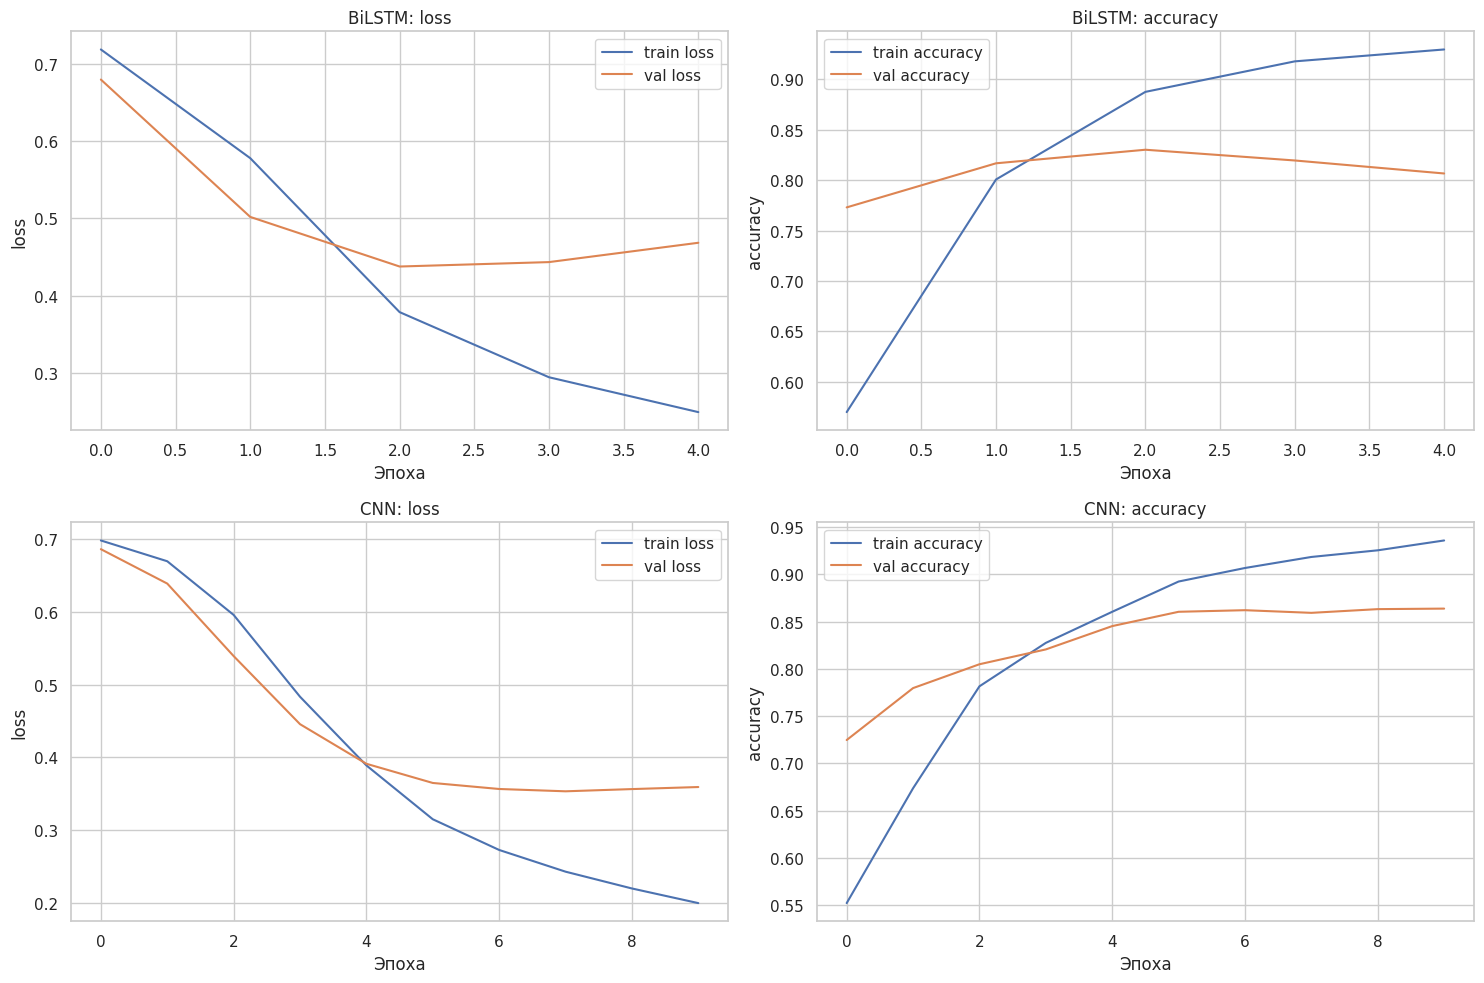

Baseline  : val accuracy=0.8459, F1=0.8508
BiLSTM    : val accuracy=0.8302, F1=0.8231
CNN       : val accuracy=0.8593, F1=0.8603


In [ ]:
# ЯЧЕЙКА 14 — кривые и качество на validation
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for row, (name, history) in enumerate([('BiLSTM',history_rnn),('CNN',history_cnn)]):
    for col, metric in enumerate(['loss','accuracy']):
        axes[row,col].plot(history.history[metric], label=f'train {metric}')
        axes[row,col].plot(history.history['val_'+metric], label=f'val {metric}')
        axes[row,col].set(title=f'{name}: {metric}',xlabel='Эпоха',ylabel=metric)
        axes[row,col].legend()
plt.tight_layout(); plt.show()

p_rnn_val = rnn_model.predict(X_val_nn, batch_size=256, verbose=0).ravel()
p_cnn_val = cnn_model.predict(X_val_nn, batch_size=256, verbose=0).ravel()

for name, probs in [('Baseline',p_base_val),('BiLSTM',p_rnn_val),('CNN',p_cnn_val)]:
    preds = (probs >= THRESHOLD).astype(int)
    print(f'{name:10s}: val accuracy={accuracy_score(y_val,preds):.4f}, '
          f'F1={f1_score(y_val,preds):.4f}')

## Ячейка 15. Подбор веса ансамбля на validation

`p_ensemble = w * p_BiLSTM + (1-w) * p_CNN`. Перебор `w=0.00...1.00` с шагом 0.05. Критерий — accuracy на val, при равенстве предпочитаем более близкий к 0.5 вес. **Ни `test`, ни его метки в подборе не участвуют.** Границы `w=0`/`1` допустимы, но означают, что одна модель фактически исключается.

Оптимальный вес BiLSTM: 0.25
Вес CNN: 0.75
Лучшая val accuracy: 0.8638


,w_rnn,val_accuracy,val_f1
4,0.20,0.863789,0.864018
5,0.25,0.863789,0.863713
8,0.40,0.862668,0.862127
6,0.30,0.861547,0.861625
7,0.35,0.861547,0.861002
2,0.10,0.860987,0.861761
3,0.15,0.860987,0.861761
9,0.45,0.860987,0.860360
1,0.05,0.859865,0.860957
0,0.00,0.859305,0.860323


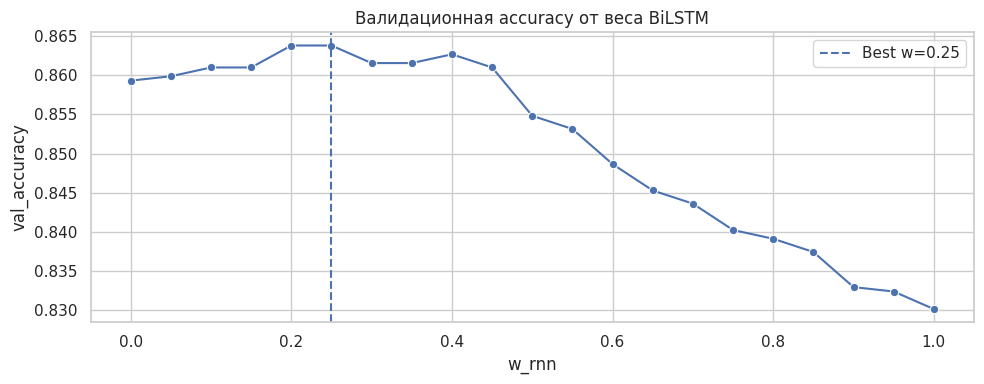

In [ ]:
# ЯЧЕЙКА 15 — оптимизация только на validation
weight_rows = []
for w in np.round(np.linspace(0,1,21), 2):
    p = w * p_rnn_val + (1 - w) * p_cnn_val
    pred = (p >= THRESHOLD).astype(int)
    weight_rows.append({
        'w_rnn':float(w),
        'val_accuracy':float(accuracy_score(y_val,pred)),
        'val_f1':float(f1_score(y_val,pred,zero_division=0))
    })
weight_table = pd.DataFrame(weight_rows)
best_row = sorted(weight_rows,
                  key=lambda d: (-d['val_accuracy'],abs(d['w_rnn']-0.5)))[0]
BEST_W = best_row['w_rnn']
p_ens_val = BEST_W*p_rnn_val + (1-BEST_W)*p_cnn_val

print('Оптимальный вес BiLSTM:',BEST_W)
print('Вес CNN:',round(1-BEST_W,2))
print('Лучшая val accuracy:',round(best_row['val_accuracy'],4))
display(weight_table.sort_values(['val_accuracy','val_f1'],ascending=False).head(10))

plt.figure(figsize=(10,4))
sns.lineplot(data=weight_table, x='w_rnn', y='val_accuracy', marker='o')
plt.axvline(BEST_W, ls='--', label=f'Best w={BEST_W:.2f}')
plt.title('Валидационная accuracy от веса BiLSTM');plt.legend();plt.tight_layout();plt.show()

## Ячейка 16. Единственная итоговая проверка на test

Выводятся accuracy, precision, recall, F1, balanced accuracy, ROC-AUC и полный classification_report для всех четырёх моделей. Это **фактические**, а не целевые оценки. Выбор архитектур/весов после просмотра тестовых метрик недопустим.

In [ ]:
# ЯЧЕЙКА 16 — неизменяемый отложенный test
X_test_tfidf = vectorizer.transform(x_test)
p_base_test = baseline.predict_proba(X_test_tfidf)[:,1]
p_rnn_test = rnn_model.predict(X_test_nn,batch_size=256,verbose=0).ravel()
p_cnn_test = cnn_model.predict(X_test_nn,batch_size=256,verbose=0).ravel()
p_ens_test = BEST_W*p_rnn_test + (1-BEST_W)*p_cnn_test

TEST_PROBAS = {
    'TF-IDF + LR':p_base_test,
    'BiLSTM':p_rnn_test,
    'CNN Kim-2014':p_cnn_test,
    'Ensemble':p_ens_test,
}

def metrics_row(name, y_true, p):
    y_pred = (p >= THRESHOLD).astype(int)
    return {
        'model':name,
        'accuracy':accuracy_score(y_true,y_pred),
        'f1':f1_score(y_true,y_pred,zero_division=0),
        'precision':precision_score(y_true,y_pred,zero_division=0),
        'recall':recall_score(y_true,y_pred,zero_division=0),
        'balanced_accuracy':balanced_accuracy_score(y_true,y_pred),
        'roc_auc':roc_auc_score(y_true,p),
    }

results = pd.DataFrame([metrics_row(name,y_test,p)
                        for name,p in TEST_PROBAS.items()])
print('ИТОГОВЫЕ МЕТРИКИ НА TEST')
display(results.set_index('model').round(4))

for name,p in TEST_PROBAS.items():
    pred = (p>=THRESHOLD).astype(int)
    print('\n'+'='*70+'\n'+name)
    print(classification_report(y_test,pred,
                                labels=[0,1],
                                target_names=['real (0)','fake (1)'],
                                zero_division=0))

if results.accuracy.max() > 0.95:
    print('ВНИМАНИЕ: accuracy > 0.95 — требуется особенно строгая проверка')
    print('источниковой/стилевой утечки, похожих формулировок и независимого корпуса!')

ИТОГОВЫЕ МЕТРИКИ НА TEST


,accuracy,f1,precision,recall,balanced_accuracy,roc_auc
model,,,,,,
TF-IDF + LR,0.8402,0.8424,0.8100,0.8775,0.8412,0.9065
BiLSTM,0.8229,0.8075,0.8569,0.7635,0.8213,0.8918
CNN Kim-2014,0.8438,0.8402,0.8362,0.8444,0.8438,0.9181
Ensemble,0.8485,0.8440,0.8461,0.8419,0.8484,0.9182



TF-IDF + LR
              precision    recall  f1-score   support

    real (0)       0.87      0.80      0.84       861
    fake (1)       0.81      0.88      0.84       816

    accuracy                           0.84      1677
   macro avg       0.84      0.84      0.84      1677
weighted avg       0.84      0.84      0.84      1677


BiLSTM
              precision    recall  f1-score   support

    real (0)       0.80      0.88      0.84       861
    fake (1)       0.86      0.76      0.81       816

    accuracy                           0.82      1677
   macro avg       0.83      0.82      0.82      1677
weighted avg       0.83      0.82      0.82      1677


CNN Kim-2014
              precision    recall  f1-score   support

    real (0)       0.85      0.84      0.85       861
    fake (1)       0.84      0.84      0.84       816

    accuracy                           0.84      1677
   macro avg       0.84      0.84      0.84      1677
weighted avg       0.84      0.84      

## Ячейка 17. Матрицы ошибок heatmap для baseline, BiLSTM, CNN, ensemble

Для `y=1` (fake): FN — фейк назван правдой; для `y=0` (real): FP — правдивый текст назван фейком.

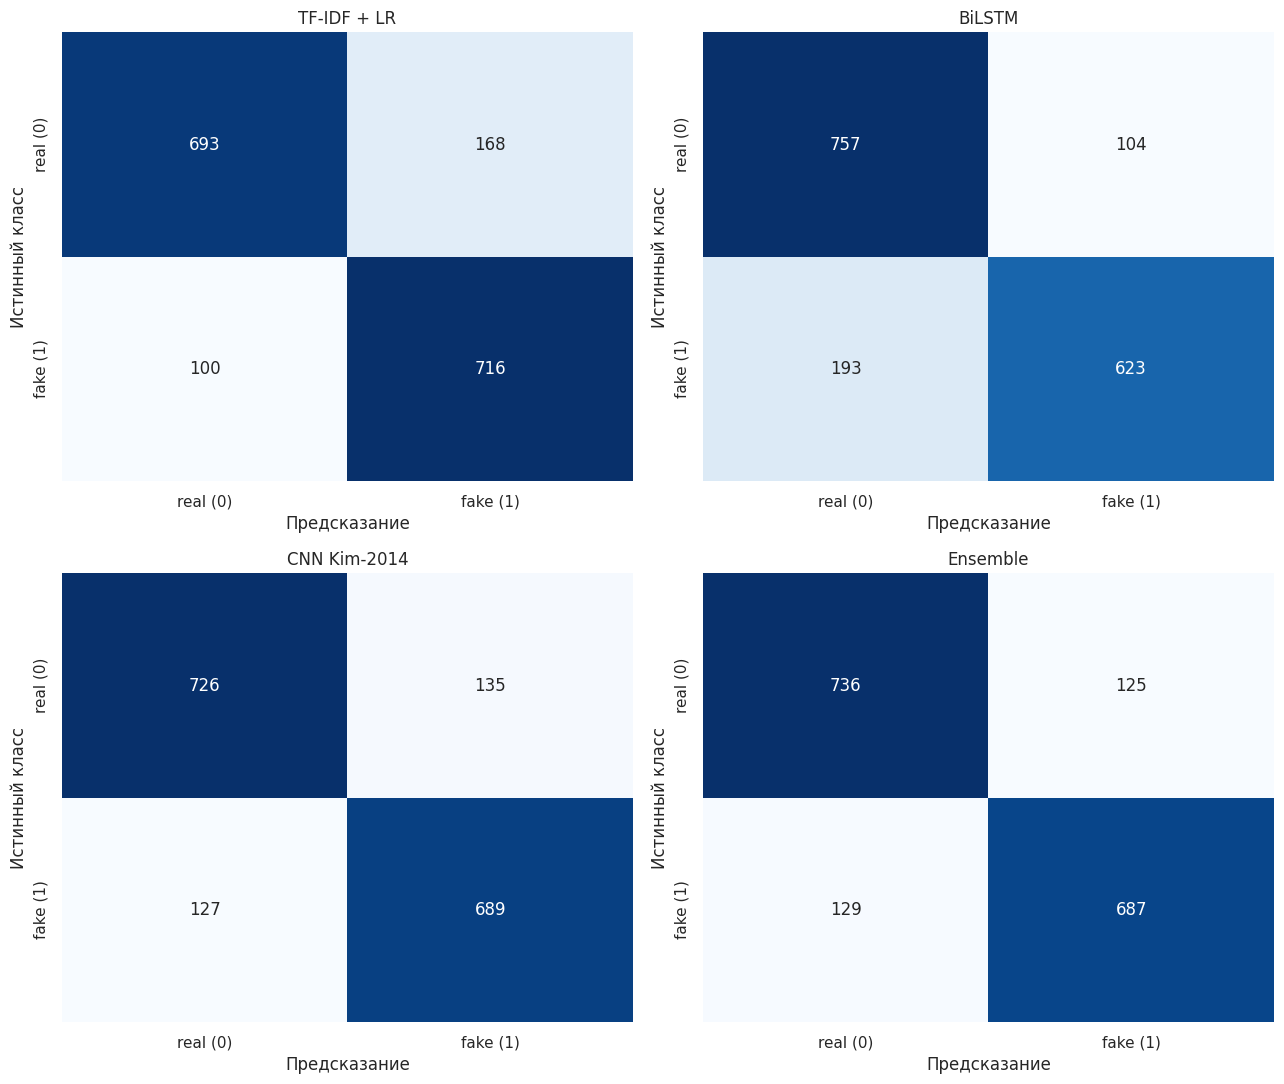

In [ ]:
# ЯЧЕЙКА 17 — четыре confusion matrix
fig, axes = plt.subplots(2,2,figsize=(13,11))
for ax,(name,p) in zip(axes.ravel(),TEST_PROBAS.items()):
    pred=(p>=THRESHOLD).astype(int)
    cm=confusion_matrix(y_test,pred,labels=[0,1])
    sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',cbar=False,ax=ax,
                xticklabels=['real (0)','fake (1)'],
                yticklabels=['real (0)','fake (1)'])
    ax.set(title=name,xlabel='Предсказание',ylabel='Истинный класс')
plt.tight_layout();plt.show()

## Ячейка 18. Ошибки ансамбля: FN, FP, уверенные ошибки, разногласия

Просмотрим отдельные тексты с вероятностями каждой модели. Большая уверенность при ошибке может означать источникоспецифичный шаблон или сложное фактическое искажение.

In [ ]:
# ЯЧЕЙКА 18 — анализ примеров ошибок
test_predictions = test_df[['title','title_clean','is_fake']].copy()
test_predictions = test_predictions.rename(columns={'is_fake':'y_true'})
test_predictions['p_baseline'] = p_base_test
test_predictions['p_rnn'] = p_rnn_test
test_predictions['p_cnn'] = p_cnn_test
test_predictions['p_ensemble'] = p_ens_test
test_predictions['y_pred'] = (p_ens_test >= THRESHOLD).astype(int)
test_predictions['correct'] = test_predictions.y_true.eq(test_predictions.y_pred)
test_predictions['error_type'] = np.select([
    (test_predictions.y_true == 1) & (test_predictions.y_pred == 0),
    (test_predictions.y_true == 0) & (test_predictions.y_pred == 1),
    (test_predictions.y_true == 1) & (test_predictions.y_pred == 1),
],['FN (fake→real)','FP (real→fake)','TP'],default='TN')

test_predictions['model_disagreement'] = (
    ((test_predictions.p_rnn >= THRESHOLD) !=
     (test_predictions.p_cnn >= THRESHOLD))
)

display(test_predictions.error_type.value_counts().rename('count').to_frame())

show_cols=['title','y_true','y_pred','p_baseline','p_rnn','p_cnn','p_ensemble']
for error_name in ['FN (fake→real)','FP (real→fake)']:
    print('\n',error_name)
    display(test_predictions.loc[test_predictions.error_type.eq(error_name), show_cols].head(15))

high_conf_errors = test_predictions.loc[
    (~test_predictions.correct) &
    ((test_predictions.p_ensemble >= 0.9) | (test_predictions.p_ensemble <= 0.1))
].copy()
high_conf_errors['confidence'] = np.maximum(
    high_conf_errors.p_ensemble,1-high_conf_errors.p_ensemble)
print('\nУверенные ошибки (p(fake)>0.9 или <0.1):',len(high_conf_errors))
display(high_conf_errors.sort_values('confidence',ascending=False)[show_cols].head(20))

print('\nРазногласия RNN vs CNN:',int(test_predictions.model_disagreement.sum()))
display(test_predictions.loc[test_predictions.model_disagreement, show_cols].head(20))

,count
error_type,
TN,736
TP,687
FN (fake→real),129
FP (real→fake),125



 FN (fake→real)


,title,y_true,y_pred,p_baseline,p_rnn,p_cnn,p_ensemble
0,Учёные ТПУ нашли способ борьбы с почечной недостаточностью новорожденных,1,0,0.835051,0.240670,0.561673,0.481422
12,В СФУ создана новая технология пайки керамики и металла,1,0,0.510346,0.308913,0.435962,0.404199
21,Российские ученые построили «наноробота» из молекул ДНК,1,0,0.232845,0.151453,0.227219,0.208278
22,Сибирские учёные разработали препарат для профилактики нарушений обмена веществ из лопуха,1,0,0.669276,0.328238,0.522552,0.473974
27,Физики получили изображения электромагнитных полей квантовых наноантенн,1,0,0.560223,0.305928,0.450276,0.414189
36,Открытие ученых ИЯФ СО РАН может снизить скорость интернета,1,0,0.218396,0.157271,0.038223,0.067985
61,Тяжелее урана. 6 июня 1940 г. объявлено об открытии нептуния,1,0,0.267076,0.091719,0.150847,0.136065
72,"Палеонтологи ДВФУ по костям динозавров подтвердили, что на Чукотке в древности был более мягкий климат, чем сегодня",1,0,0.448534,0.206571,0.522188,0.443284
85,"Ученые ФИЦ Биотехнологии РАН определили, какие микроорганизмы лучше всего очищают сточные воды города Самары",1,0,0.261194,0.014771,0.122820,0.095808
89,"Ученые МГУ и ТИБОХ ДВО РАН доказали, что тропические актинии могут помочь в борьбе с болезнью Альцгеймера",1,0,0.678731,0.282367,0.492178,0.439725



 FP (real→fake)


,title,y_true,y_pred,p_baseline,p_rnn,p_cnn,p_ensemble
3,Ученые из Томска научились находить трещины в авиастеклах с помощью голографии,0,1,0.627570,0.896325,0.824972,0.842810
5,Прототип нового безопасного мессенджера предложили в МГУ,0,1,0.891447,0.692269,0.812816,0.782679
35,Исследователи РФ и Великобритании нашли новый способ защиты от теплового излучения пламени,0,1,0.556775,0.485066,0.739555,0.675933
43,Биологи МГУ открыли механизм передачи каротиноида между двумя белками,0,1,0.500798,0.395308,0.656253,0.591017
44,Биологи ТГУ предложили формулу для прогноза урожайности пойменных лугов,0,1,0.856233,0.407108,0.814128,0.712373
45,Ученые выяснили природу пылевых облаков на Луне,0,1,0.586037,0.689520,0.831289,0.795847
81,Ученые из Уфы создали прибор для диагностики язвы и опухолей желудка по дыханию пациента,0,1,0.671044,0.713243,0.591360,0.621831
104,Разработчики из Пермского Политеха создают сверхлегкий электромотоцикл,0,1,0.717300,0.556445,0.849812,0.776470
131,В МФТИ упростили описание «строительных кубиков» оптических наносистем,0,1,0.807901,0.764062,0.735485,0.742629
137,Ученый ТПУ получил новые экспериментальные данные об испарении водных растворов солей,0,1,0.574150,0.831824,0.643430,0.690529



Уверенные ошибки (p(fake)>0.9 или <0.1): 35


,title,y_true,y_pred,p_baseline,p_rnn,p_cnn,p_ensemble
841,Химики из СПбГУ создали новый материал для производства магний-ионных аккумуляторных батарей,0,1,0.945347,0.918546,0.991982,0.973623
1401,"Ученые СПбГУ выяснили, как эффективнее запоминать новые слова",0,1,0.861386,0.892516,0.990352,0.965893
1554,"Белок, помогающий бороться с вирусами, может блокировать восстановление печени",1,0,0.163705,0.048733,0.035982,0.039169
859,"Планета или коричневый карлик: обнаружен объект, похожий на молодой Марс",1,0,0.197703,0.032842,0.044889,0.041877
1406,"В НИЯУ ""МИФИ"" нашли способ повысить безопасность реакторов",0,1,0.723175,0.927246,0.966158,0.956430
529,"Белок, помогающий бороться с вирусами, может блокировать восстановление мозга",1,0,0.190068,0.072664,0.043774,0.050997
1394,"Ученые ТПУ разработали технологию получения медицинских материалов, наполненных антибактериальными средствами",0,1,0.975390,0.858748,0.973412,0.944746
100,"Белок, помогающий бороться с вирусами, может блокировать восстановление сердца",1,0,0.235551,0.079192,0.053702,0.060075
1250,"Ученые из Красноярска выделили штамм бактерий, способных производить бактериальную целлюлозу",0,1,0.706352,0.938539,0.938136,0.938237
1573,Магнитное поле управляет «внутренним миром» жидких кристаллов,1,0,0.314412,0.089889,0.057431,0.065545



Разногласия RNN vs CNN: 169


,title,y_true,y_pred,p_baseline,p_rnn,p_cnn,p_ensemble
0,Учёные ТПУ нашли способ борьбы с почечной недостаточностью новорожденных,1,0,0.835051,0.240670,0.561673,0.481422
22,Сибирские учёные разработали препарат для профилактики нарушений обмена веществ из лопуха,1,0,0.669276,0.328238,0.522552,0.473974
30,"Созданы сенсоры, способные распознавать цинк и «сигнализировать» об этом",0,0,0.359028,0.120704,0.515417,0.416739
35,Исследователи РФ и Великобритании нашли новый способ защиты от теплового излучения пламени,0,1,0.556775,0.485066,0.739555,0.675933
43,Биологи МГУ открыли механизм передачи каротиноида между двумя белками,0,1,0.500798,0.395308,0.656253,0.591017
44,Биологи ТГУ предложили формулу для прогноза урожайности пойменных лугов,0,1,0.856233,0.407108,0.814128,0.712373
69,Ученые из МГУ разрабатывают технологии выращивания редких растений,1,1,0.807396,0.457438,0.737187,0.667249
72,"Палеонтологи ДВФУ по костям динозавров подтвердили, что на Чукотке в древности был более мягкий климат, чем сегодня",1,0,0.448534,0.206571,0.522188,0.443284
79,"Радиофизики МГУ создали прибор, с помощью которого можно почувствовать щекотку, жжение и боль",1,1,0.780536,0.437823,0.813408,0.719512
98,ИТМО провел первый в России онлайн-курс при помощи цифровых аватаров,0,0,0.578062,0.756442,0.399231,0.488534


## Ячейка 19. Частые слова в ошибках против правильных ответов

Показываются абсолютные частоты, а также относительное обогащение слова в ошибках (сглаженный log-ratio). Последнее снижает эффект разного количества текстов в группах. Для интерпретации причин нужны ручная проверка и независимые источники.

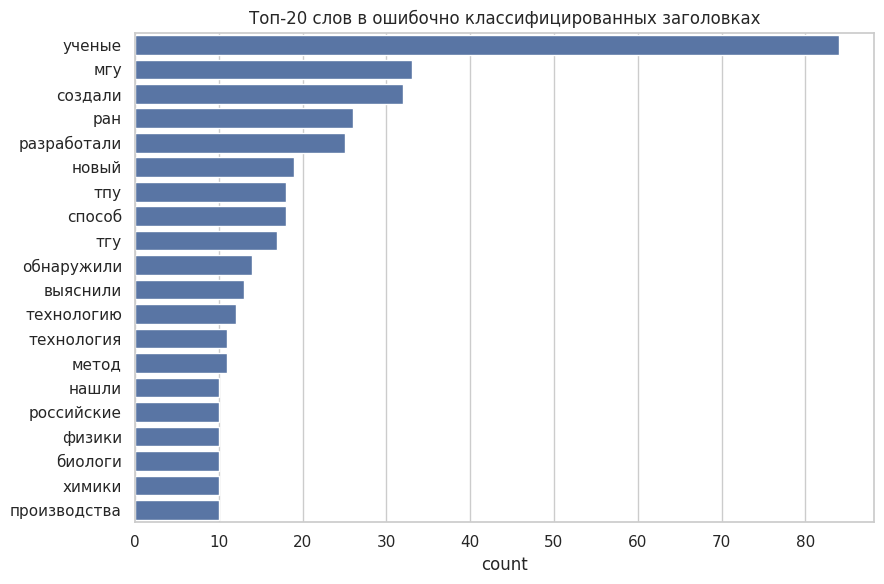

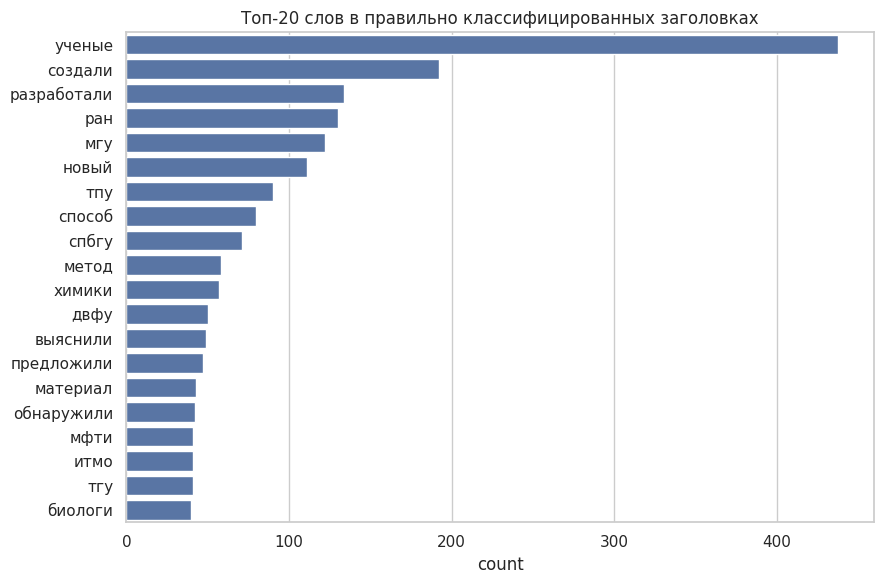

,word,errors_count,correct_count,log_ratio
35,технологичность,8,0,3.948050
39,интегральных,8,0,3.948050
147,схем,8,0,3.948050
0,фиц,7,0,3.822887
70,биотехнологии,6,0,3.679786
87,города,5,0,3.512732
143,лучше,5,0,3.512732
151,очищают,5,0,3.512732
22,древности,4,0,3.312061
122,подтвердили,4,0,3.312061


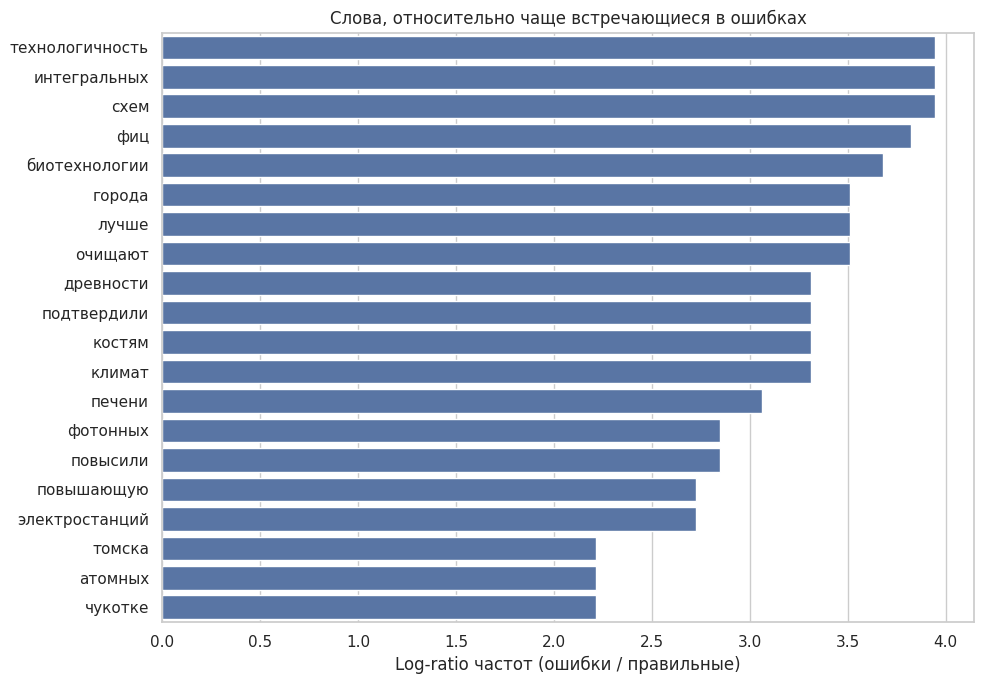

In [ ]:
# ЯЧЕЙКА 19 — слова в ошибках / правильных ответах
wrong = test_predictions.loc[~test_predictions.correct, 'title_clean']
right = test_predictions.loc[test_predictions.correct, 'title_clean']

wrong_freq = Counter(' '.join(wrong).split())
right_freq = Counter(' '.join(right).split())

def plot_freq(freq, title, top_n=20):
    top = pd.DataFrame(freq.most_common(top_n),columns=['word','count'])
    if top.empty:
        print('Недостаточно слов для:',title)
        return
    plt.figure(figsize=(9,6))
    sns.barplot(data=top,x='count',y='word')
    plt.title(title);plt.ylabel('');plt.tight_layout();plt.show()

plot_freq(wrong_freq,'Топ-20 слов в ошибочно классифицированных заголовках')
plot_freq(right_freq,'Топ-20 слов в правильно классифицированных заголовках')

wrong_total = sum(wrong_freq.values())
right_total = sum(right_freq.values())
vocab = set(wrong_freq)|set(right_freq)
min_wrong_count = 3
score_rows=[]
for word in vocab:
    wc=wrong_freq[word]
    if wc < min_wrong_count:
        continue
    rc=right_freq[word]
    # Логарифм отношения сглаженных относительных частот
    score = np.log((wc+0.5)/(wrong_total+0.5*len(vocab))) - np.log(
        (rc+0.5)/(right_total+0.5*len(vocab)))
    score_rows.append((word,wc,rc,score))
score_df=pd.DataFrame(score_rows,columns=['word','errors_count','correct_count','log_ratio'])
if len(score_df):
    top_err=score_df.sort_values('log_ratio',ascending=False).head(20)
    display(top_err)
    plt.figure(figsize=(10,7))
    sns.barplot(data=top_err,x='log_ratio',y='word')
    plt.title('Слова, относительно чаще встречающиеся в ошибках')
    plt.xlabel('Log-ratio частот (ошибки / правильные)');plt.ylabel('')
    plt.tight_layout();plt.show()

## Ячейка 20. Аудит похожих заголовков между train и test

Точное совпадение уже исключено. Здесь смотрим максимальную **char n-gram cosine similarity** каждого test-заголовка с `train + val` после группового разделения. Это не идеальный детектор перефразировок, но выявляет значительную часть технических near-duplicates. При корректной группировке не должно быть пар выше порога 0.90; если найдено много близких текстов, результаты нужно подтвердить на **независимом внешнем корпусе** или перестроить split по кластерам похожих сообщений.

In [ ]:
# ЯЧЕЙКА 20 — межвыборочная близость / поиск потенциальной утечки
# Словарь для проверки сходства только по train; это НЕ вход в классификаторы.
char_vec = TfidfVectorizer(analyzer='char',ngram_range=(3,5),
                           max_features=50_000, sublinear_tf=True,
                           dtype=np.float32)
char_train = char_vec.fit_transform(x_train)
char_val = char_vec.transform(x_val)
char_test = char_vec.transform(x_test)
char_ref = sp.vstack([char_train,char_val],format='csr')
ref_titles = np.concatenate([x_train,x_val])

similarities=[]
nearest_idx=[]
for start in range(0,char_test.shape[0],64):
    batch = char_test[start:start+64]
    sim = batch @ char_ref.T  # sparse, только по небольшим batch
    maxsim = np.asarray(sim.max(axis=1).toarray()).ravel()
    nearest = np.asarray(sim.argmax(axis=1)).ravel()
    similarities.extend(maxsim.tolist())
    nearest_idx.extend(nearest.tolist())

test_predictions['max_char_similarity_to_trainval'] = similarities
test_predictions['nearest_trainval_clean'] = ref_titles[np.array(nearest_idx,dtype=int)]
print('Макс. сходство test c train/val (квантили):')
print(test_predictions.max_char_similarity_to_trainval.quantile([0,.5,.9,.95,.99,1]).round(3))
for cutoff in [0.85,0.90,0.95]:
    hits = int((test_predictions.max_char_similarity_to_trainval>=cutoff).sum())
    print(f'Сходство >= {cutoff}: {hits} ({hits/len(test_predictions):.2%})')

print('\nПримеры наиболее похожих пар:')
display(test_predictions.sort_values('max_char_similarity_to_trainval',ascending=False)[
    ['title','nearest_trainval_clean','max_char_similarity_to_trainval','y_true','correct']
].head(15))

if (test_predictions.max_char_similarity_to_trainval>=0.95).any():
    print('ПРЕДУПРЕЖДЕНИЕ: обнаружены очень похожие пары через границу split.')
    print('Не интерпретируйте test как полностью независимый по содержанию.')

Макс. сходство test c train/val (квантили):
0.00    0.141
0.50    0.324
0.90    0.835
0.95    0.870
0.99    0.891
1.00    0.901
Name: max_char_similarity_to_trainval, dtype: float64
Сходство >= 0.85: 144 (8.59%)
Сходство >= 0.9: 2 (0.12%)
Сходство >= 0.95: 0 (0.00%)

Примеры наиболее похожих пар:


,title,nearest_trainval_clean,max_char_similarity_to_trainval,y_true,correct
1183,На Камчатке учеными ИТМО обнаружены неизвестные науке токсины,камчатке учеными тгу обнаружены неизвестные науке токсины,0.901033,1,True
1095,Ученые СФУ исследовали лошадей кобанской культуры,ученые спбгу исследовали лошадей кобанской культуры,0.900295,1,False
1460,"Медь, отравляющая жизнь: ученые МГУ внедряют точный и недорогой метод анализа ДНК",железо отравляющая жизнь ученые двфу внедряют точный недорогой метод анализа днк,0.899077,1,True
1250,"Ученые из Красноярска выделили штамм бактерий, способных производить бактериальную целлюлозу",ученые томска выделили штамм бактерий способных производить бактериальную целлюлозу,0.898154,0,False
419,"Бактерии в кишечниках россиян скрывают защиту от антибиотков, выяснили генетики",грибы кишечниках россиян скрывают защиту антибиотков выяснили генетики,0.898069,0,False
1321,Новые особенности синтеза бактериальной целлюлозы выявили уральские ученые,новые особенности синтеза бактериальной целлюлозы выявили сибирские ученые,0.896642,1,True
1113,Биологи МГУ изучили скелеты древнейших организмов,биологи мфти изучили скелеты древнейших организмов,0.895772,0,False
1109,"Медь, отравляющая жизнь: ученые ТПУ внедряют точный и недорогой метод анализа ДНК",железо отравляющая жизнь ученые двфу внедряют точный недорогой метод анализа днк,0.895503,1,True
229,Новосибирские учёные создали новые лекарства на основе лишайников,пермские ученые создали новые лекарства основе лишайников,0.895282,1,True
1538,"Ученый Томского Политеха разработал авиационную лопасть, меняющую форму в полете",ученый московского политеха разработал авиационную лопасть меняющую форму полете,0.894657,1,True


## Ячейка 21. Проверка источникового/стилевого риска и точности >95%

Тестируем простой диагностический стиль без содержания слов; сравниваем с лучшей NLP-моделью. Это не оценка factual correctness: оригинальные источники, публикации и независимая разметка в CSV отсутствуют.

In [ ]:
# ЯЧЕЙКА 21 — диагностика подозрительно высокой accuracy
p_style_test = style_model.predict_proba(style_test)[:,1]
style_acc_test = accuracy_score(y_test,p_style_test>=0.5)
style_auc_test = roc_auc_score(y_test,p_style_test)
print(f'Style-only test: accuracy={style_acc_test:.4f} ROC-AUC={style_auc_test:.4f}')
print('Лучшая NLP test accuracy:',f'{results.accuracy.max():.4f}')
print('Статистика стиля помогает диагностировать риск, но не доказывает конкретную утечку.')

if style_auc_test >= 0.70:
    print('РИСК: даже простые стилистические признаки позволяют предсказывать метку.')
if results.accuracy.max() > 0.95:
    print('РИСК: слишком высокая accuracy — проверьте общие источники и синтетический стиль.')

# Контроль источников: если source нет, фактически группировка по источникам невозможна.
print('Колонка source отсутствует: независимость по источникам проверить по CSV нельзя.')
print('Дата публикации отсутствует: нельзя оценить временное покрытие или temporal shift.')
print('ASR-аудио и эталонных транскрипций нет: WER/CER не вычисляются.')

Style-only test: accuracy=0.7001 ROC-AUC=0.7530
Лучшая NLP test accuracy: 0.8485
Статистика стиля помогает диагностировать риск, но не доказывает конкретную утечку.
РИСК: даже простые стилистические признаки позволяют предсказывать метку.
Колонка source отсутствует: независимость по источникам проверить по CSV нельзя.
Дата публикации отсутствует: нельзя оценить временное покрытие или temporal shift.
ASR-аудио и эталонных транскрипций нет: WER/CER не вычисляются.


**ОТЧЁТ: Классификация научных новостных заголовков (fake / real)**

1. ДАТАСЕТ
Размер: 11 723 → 11 428 строк после очистки. Структура: title, is_fake.
Баланс: 5865 / 5858. Единица сегментации — заголовок научной новости.
Источники - реальные новости были собраны путём парсинга из сайта https://scientificrussia.ru/, а фейковые новости созданы синтетически (GPT).
Технический шум: 0.07%; чистых: 99.93% (URL, HTML, <3 слов, без кириллицы).

2. ПРЕДОБРАБОТКА
Lowercase, ё→е, удаление URL/цифр/пунктуации, стоп-слова с сохранением
отрицаний (не, ни, нет, без), дедупликация, устранение конфликтных меток.

3. МЕТОД И ОБОСНОВАНИЕ ВЫБОРА
- TF-IDF + LR (baseline): TF-IDF эффективен для коротких текстов;
  LR устойчив на малых данных, интерпретируем через коэффициенты.
  Проверен как «метод с вебинара 4».
- BiLSTM: захватывает порядок слов, полезен при отрицаниях
  («X не влияет на Y»). Hidden=32, чтобы не переобучиться.
- CNN Kim (2014): окна 2/3/4/5, 64 фильтра. Извлекает локальные
  n-граммы-маркеры («ученые МГУ создали», «в ТПУ разработали»).
- Ансамбль: RNN и CNN ошибаются на разных объектах (169 разногласий),
  веса выбраны по validation accuracy: w_BiLSTM=0.25, w_CNN=0.75.
  Test не использовался при подборе.

4. РЕЗУЛЬТАТЫ (test)
TF-IDF+LR:  Acc=0.8402 F1=0.8424 AUC=0.9065
BiLSTM:     Acc=0.8229 F1=0.8075 AUC=0.8918
CNN:        Acc=0.8438 F1=0.8402 AUC=0.9181
Ensemble:   Acc=0.8485 F1=0.8440 AUC=0.9182  ← лучший

5. ОШИБКИ
FN=129, FP=125, уверенных ошибок=35, разногласий RNN/CNN=169.
Стилевой диагностический классификатор: AUC=0.7530 — риск
стилевой утечки, нужен независимый корпус для фактчекинга.

6. ОГРАНИЧЕНИЯ
Нет источников и дат → независимость по источникам не проверена.
Нет транскрипций → ASR-этап не оценивался.

**Обоснование выбора методов**

TF-IDF + LR выбран как обязательный метод с вебинара 4: TF-IDF хорошо работает на коротких разреженных текстах, логистическая регрессия устойчива к малому объёму данных и даёт интерпретируемые коэффициенты, что позволило вручную проанализировать, какие слова модель считает маркерами фейка (Ячейка 8).

BiLSTM добавлен, потому что линейные модели игнорируют порядок слов, а в заголовках важны конструкции с отрицанием и модальностью («не влияет», «может блокировать»).

CNN Kim добавлен, потому что заголовки короткие и ключевой сигнал локализован в n-граммах («в ТПУ разработали», «ученые МГУ открыли»); CNN эффективно извлекает такие паттерны.

Ансамбль обоснован тем, что RNN и CNN ошибаются на разных объектах (169 разногласий), что снижает дисперсию итогового предсказания. Веса подобраны только на validation перебором w=0…1 с шагом 0.05.

